In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import sklearn

print("SentinelNet Environment Ready!")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

SentinelNet Environment Ready!
Pandas: 3.1.1
NumPy: 2.5.4
Scikit-learn: 1.9.1


In [2]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# System Operations
from pathlib import Path
import os

print("SentinelNet - Data Collection Started")

SentinelNet - Data Collection Started


In [3]:
# Project Directory
PROJECT_DIR = Path.cwd().parent

# Dataset Directory
DATA_DIR = PROJECT_DIR / "data" / "raw"

# Dataset Files
TRAIN_PATH = DATA_DIR / "KDDTrain+.txt"
TEST_PATH = DATA_DIR / "KDDTest+.txt"

print("Project Directory:", PROJECT_DIR)
print("Data Directory:", DATA_DIR)

print("Training File Exists:", TRAIN_PATH.exists())
print("Testing File Exists:", TEST_PATH.exists())


Project Directory: c:\Users\DELL\Downloads\SentinelNet
Data Directory: c:\Users\DELL\Downloads\SentinelNet\data\raw
Training File Exists: True
Testing File Exists: True


Define Dataset Columns

In [4]:
columns = [
    "duration",
    "protocol_type",
    "service",
    "flag",
    "src_bytes",
    "dst_bytes",
    "land",
    "wrong_fragment",
    "urgent",
    "hot",
    "num_failed_logins",
    "logged_in",
    "num_compromised",
    "root_shell",
    "su_attempted",
    "num_root",
    "num_file_creations",
    "num_shells",
    "num_access_files",
    "num_outbound_cmds",
    "is_host_login",
    "is_guest_login",
    "count",
    "srv_count",
    "serror_rate",
    "srv_serror_rate",
    "rerror_rate",
    "srv_rerror_rate",
    "same_srv_rate",
    "diff_srv_rate",
    "srv_diff_host_rate",
    "dst_host_count",
    "dst_host_srv_count",
    "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate",
    "dst_host_srv_serror_rate",
    "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate",
    "label",
    "difficulty"
]

print("Total Columns:", len(columns))

Total Columns: 43


Load Training Data

In [5]:
train_df = pd.read_csv(
    TRAIN_PATH,
    header=None,
    names=columns
)

print("Training Dataset Loaded Successfully!")

Training Dataset Loaded Successfully!


Load Testing Data

In [6]:
test_df = pd.read_csv(
    TEST_PATH,
    header=None,
    names=columns
)

print("Testing Dataset Loaded Successfully!")

Testing Dataset Loaded Successfully!


Dataset Overview

In [7]:
print("Training Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)

print("\nFirst 5 Records:")
display(train_df.head())

Training Shape: (125973, 43)
Testing Shape: (22544, 43)

First 5 Records:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


Dataset Information

In [8]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  str    
 2   service                      125973 non-null  str    
 3   flag                         125973 non-null  str    
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-null  int64  
 11  logged_in                    125973 non-null  int64  
 12  num_compromised              125973 non-null  int64  
 13  root_shell

phase 2 : Data Quality Assessment

 Check missing values

In [9]:
# Check missing values

missing_values = train_df.isnull().sum()

print("Total Missing Values:", missing_values.sum())

display(
    missing_values[missing_values > 0]
)

Total Missing Values: 0


Series([], dtype: int64)

Check duplicate records

In [10]:
# Check duplicate records

train_duplicates = train_df.duplicated().sum()
test_duplicates = test_df.duplicated().sum()

print("Training Duplicates:", train_duplicates)
print("Testing Duplicates:", test_duplicates)

Training Duplicates: 0
Testing Duplicates: 0


Check data types

In [11]:
# Check data types

display(train_df.dtypes.value_counts())

print("\nCategorical Columns:")

categorical_columns = train_df.select_dtypes(
    include="object"
).columns.tolist()

print(categorical_columns)

print("\nNumerical Columns:")

numerical_columns = train_df.select_dtypes(
    include=np.number
).columns.tolist()

print(numerical_columns)

int64      24
float64    15
str         4
Name: count, dtype: int64


Categorical Columns:
['protocol_type', 'service', 'flag', 'label']

Numerical Columns:
['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'difficulty']


C:\Users\DELL\AppData\Local\Temp\ipykernel_2536\404505166.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = train_df.select_dtypes(


 Attack Type Distribution

In [12]:
# Attack Type Distribution

attack_counts = train_df["label"].value_counts()

print("Number of Attack Classes:", len(attack_counts))

display(attack_counts)

Number of Attack Classes: 23


label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64

Draw Attacks

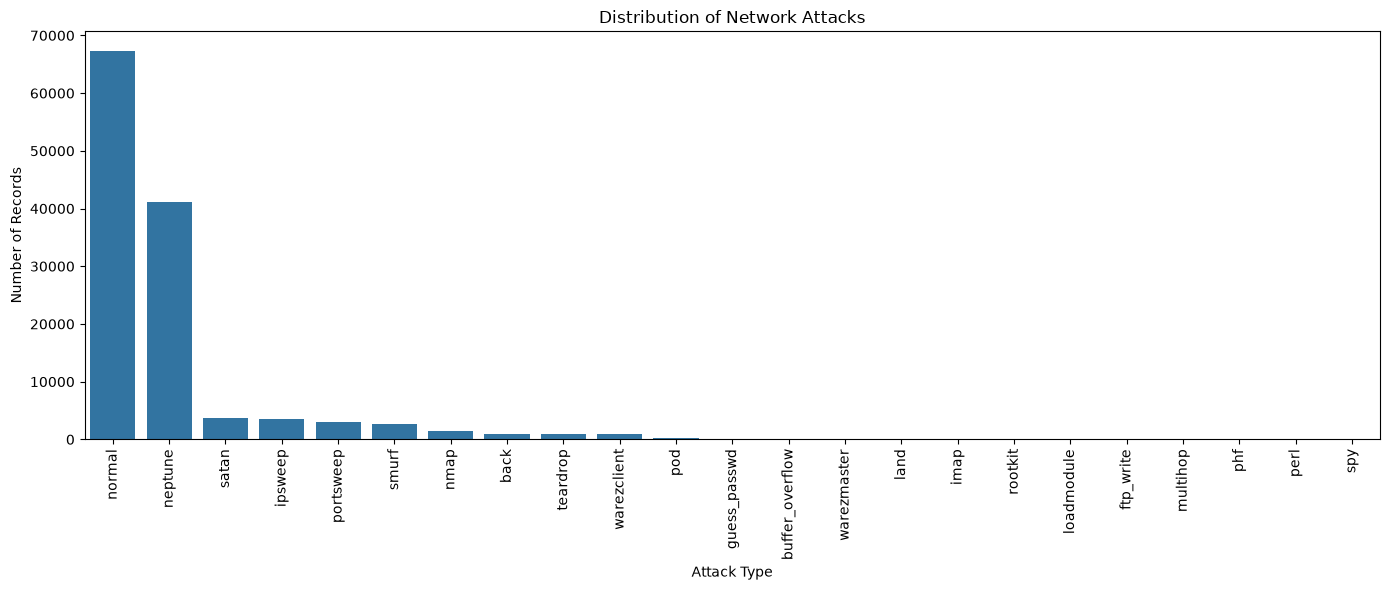

In [13]:
plt.figure(figsize=(14, 6))

sns.countplot(
    data=train_df,
    x="label",
    order=train_df["label"].value_counts().index
)

plt.title("Distribution of Network Attacks")
plt.xlabel("Attack Type")
plt.ylabel("Number of Records")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

Check Diff Values 

In [14]:
print("Protocol Types:")

display(train_df["protocol_type"].value_counts())

print("\nNumber of Services:")

print(train_df["service"].nunique())

print("\nConnection Flags:")

display(train_df["flag"].value_counts())

Protocol Types:


protocol_type
tcp     102689
udp      14993
icmp      8291
Name: count, dtype: int64


Number of Services:
70

Connection Flags:


flag
SF        74945
S0        34851
REJ       11233
RSTR       2421
RSTO       1562
S1          365
SH          271
S2          127
RSTOS0      103
S3           49
OTH          46
Name: count, dtype: int64

Attack Category Mapping

In [15]:
# Define attack categories

attack_mapping = {

    # Normal Traffic
    "normal": "Normal",

    # Denial of Service
    "back": "DoS",
    "land": "DoS",
    "neptune": "DoS",
    "pod": "DoS",
    "smurf": "DoS",
    "teardrop": "DoS",
    "mailbomb": "DoS",
    "apache2": "DoS",
    "processtable": "DoS",
    "udpstorm": "DoS",
    "worm": "DoS",

    # Probe Attacks
    "ipsweep": "Probe",
    "nmap": "Probe",
    "portsweep": "Probe",
    "satan": "Probe",
    "mscan": "Probe",
    "saint": "Probe",

    # Remote to Local
    "ftp_write": "R2L",
    "guess_passwd": "R2L",
    "imap": "R2L",
    "multihop": "R2L",
    "phf": "R2L",
    "spy": "R2L",
    "warezclient": "R2L",
    "warezmaster": "R2L",
    "httptunnel": "R2L",
    "named": "R2L",
    "sendmail": "R2L",
    "snmpgetattack": "R2L",
    "snmpguess": "R2L",
    "xlock": "R2L",
    "xsnoop": "R2L",

    # User to Root
    "buffer_overflow": "U2R",
    "loadmodule": "U2R",
    "perl": "U2R",
    "rootkit": "U2R",
    "ps": "U2R",
    "sqlattack": "U2R",
    "xterm": "U2R"
}

print("Total Mapped Attack Types:", len(attack_mapping))

Total Mapped Attack Types: 40


Apply Mapping

In [16]:
# Create the new target variable

train_df["attack_type"] = train_df["label"].map(attack_mapping)

test_df["attack_type"] = test_df["label"].map(attack_mapping)

print("Training Mapping Results:")
display(train_df["attack_type"].value_counts(dropna=False))

print("\nTesting Mapping Results:")
display(test_df["attack_type"].value_counts(dropna=False))

Training Mapping Results:


attack_type
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64


Testing Mapping Results:


attack_type
Normal    9711
DoS       7460
R2L       2885
Probe     2421
U2R         67
Name: count, dtype: int64

Check Unmapped Attacks

In [17]:
# Check unmapped attacks

unmapped_train = train_df.loc[
    train_df["attack_type"].isna(),
    "label"
].unique()

unmapped_test = test_df.loc[
    test_df["attack_type"].isna(),
    "label"
].unique()

print("Unmapped Training Attacks:", unmapped_train)

print("Unmapped Testing Attacks:", unmapped_test)

Unmapped Training Attacks: <ArrowStringArray>
[]
Length: 0, dtype: str
Unmapped Testing Attacks: <ArrowStringArray>
[]
Length: 0, dtype: str


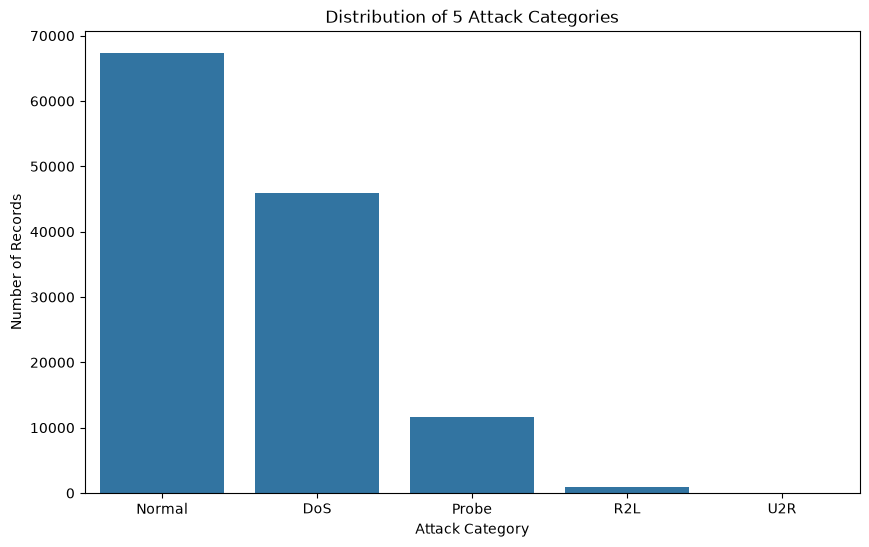

In [18]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=train_df,
    x="attack_type",
    order=["Normal", "DoS", "Probe", "R2L", "U2R"]
)

plt.title("Distribution of 5 Attack Categories")

plt.xlabel("Attack Category")
plt.ylabel("Number of Records")

plt.show()

Phase 3 : Data Preprocessing

Normalize attack labels

In [19]:
# Normalize attack labels

train_df["label"] = train_df["label"].str.strip().str.lower()
test_df["label"] = test_df["label"].str.strip().str.lower()

# Apply attack mapping again

train_df["attack_type"] = train_df["label"].map(attack_mapping)
test_df["attack_type"] = test_df["label"].map(attack_mapping)

# Check unmapped attacks

print("Training unmapped:", train_df["attack_type"].isna().sum())
print("Testing unmapped:", test_df["attack_type"].isna().sum())

Training unmapped: 0
Testing unmapped: 0


Feature and Target Separation

In [20]:
# Define feature columns

feature_columns = columns[:41]

# Separate training features and target

X_train = train_df[feature_columns].copy()
y_train = train_df["attack_type"].copy()

# Separate testing features and target

X_test = test_df[feature_columns].copy()
y_test = test_df["attack_type"].copy()

print("Training Features:", X_train.shape)
print("Training Target:", y_train.shape)

print("Testing Features:", X_test.shape)
print("Testing Target:", y_test.shape)

Training Features: (125973, 41)
Training Target: (125973,)
Testing Features: (22544, 41)
Testing Target: (22544,)


Identify categorical features

In [21]:
# Identify categorical features

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Identify numerical features

numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical Features:", categorical_features)

print("\nNumber of Categorical Features:",
      len(categorical_features))

print("\nNumber of Numerical Features:",
      len(numerical_features))

Categorical Features: ['protocol_type', 'service', 'flag']

Number of Categorical Features: 3

Number of Numerical Features: 38


Check feature consistency

In [22]:
# Check feature consistency

print(
    "Same Columns:",
    X_train.columns.equals(X_test.columns)
)

print(
    "Same Data Types:",
    X_train.dtypes.equals(X_test.dtypes)
)

print(
    "Training Shape:",
    X_train.shape
)

print(
    "Testing Shape:",
    X_test.shape
)

Same Columns: True
Same Data Types: True
Training Shape: (125973, 41)
Testing Shape: (22544, 41)


Create processed data directory

In [23]:
# Create processed data directory

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Save processed datasets

train_df.to_csv(
    PROCESSED_DIR / "train_labeled.csv",
    index=False
)

test_df.to_csv(
    PROCESSED_DIR / "test_labeled.csv",
    index=False
)

print("Processed datasets saved successfully!")

Processed datasets saved successfully!


Final class distribution

In [24]:
# Final class distribution

class_distribution = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Testing": y_test.value_counts()
}).fillna(0).astype(int)

display(class_distribution)

,Training,Testing
attack_type,,
DoS,45927,7460
Normal,67343,9711
Probe,11656,2421
R2L,995,2885
U2R,52,67
